# NDVI–NDMI clustering analysis

This notebook runs the same clustering / evaluation function as `main.py`. The full ingestion, cleansing and feature constructions will run from `python main.py`

Please run: python -m pip install -r requirements.txt in the command line / terminal before executing this notebook to install relevant dependencies - mn3392g

In [5]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

project = Path.cwd().resolve()
if not (project / "main.py").exists():
    project = project.parent
assert (project / "main.py").exists(), "Open from the project root or eda/"

sys.path.insert(0, str(project))

from main import run_analysis
from src import config
print("Project:", project)

Project: C:\Users\User\MSF_OneDrive\OneDrive\BSc Computer Science\Year 3\AI-1818\Research\ndvi_mz_mn3392g\ndvi_mz_mn3392g


## 1. Gold features

Only two pixel-level features are clustered: NDVI and NDMI

In [6]:
frames = {field: pd.read_parquet(config.GOLD_FEATURES_DIR / f"{field}_gold.parquet")
          for field in config.FIELDS}
display(pd.concat([f.assign(field=field)[["field", "ndvi", "ndmi"]] for field, f in frames.items()]).groupby("field").agg(["count", "min", "mean", "max"]))

ndvi                                ndmi                      \
        count       min      mean       max count       min      mean   
field                                                                   
oat_107   143  0.492090  0.666592  0.883069   143 -0.073457  0.100727   
oat_176   296  0.415491  0.639531  0.742802   296 -0.115640  0.045222   

                   
              max  
field              
oat_107  0.436659  
oat_176  0.232020

## 2. Method and parameter search

The starting run uses raw NDVI/NDMI, k=4 and one random K-Means start. For the tuned run, standardized NDVI/NDMI and a normalized inertia elbow select k=3 from k=2–5. The same grid also searches initialization and restarts. Maximum silhouette across k favours k=2

oat_176 — K-Means search


,k,init,n_init,silhouette,inertia,iterations,min_zone_fraction,feasible,elbow_distance
0,2,k-means++,10,0.649881,213.794722,3,0.172297,True,0.000000
1,2,k-means++,30,0.649881,213.794722,3,0.172297,True,0.000000
2,2,random,10,0.649881,213.794722,10,0.172297,True,0.000000
3,2,random,30,0.649881,213.794722,10,0.172297,True,0.000000
4,3,k-means++,10,0.439290,134.849251,7,0.172297,True,0.254383
5,3,k-means++,30,0.439290,134.849251,7,0.172297,True,0.254383
6,3,random,10,0.439290,134.855645,7,0.172297,True,0.254383
7,3,random,30,0.439290,134.855645,7,0.172297,True,0.254383
8,4,k-means++,10,0.421858,100.544137,15,0.111486,True,0.176438
9,4,k-means++,30,0.421858,100.544137,15,0.111486,True,0.176438


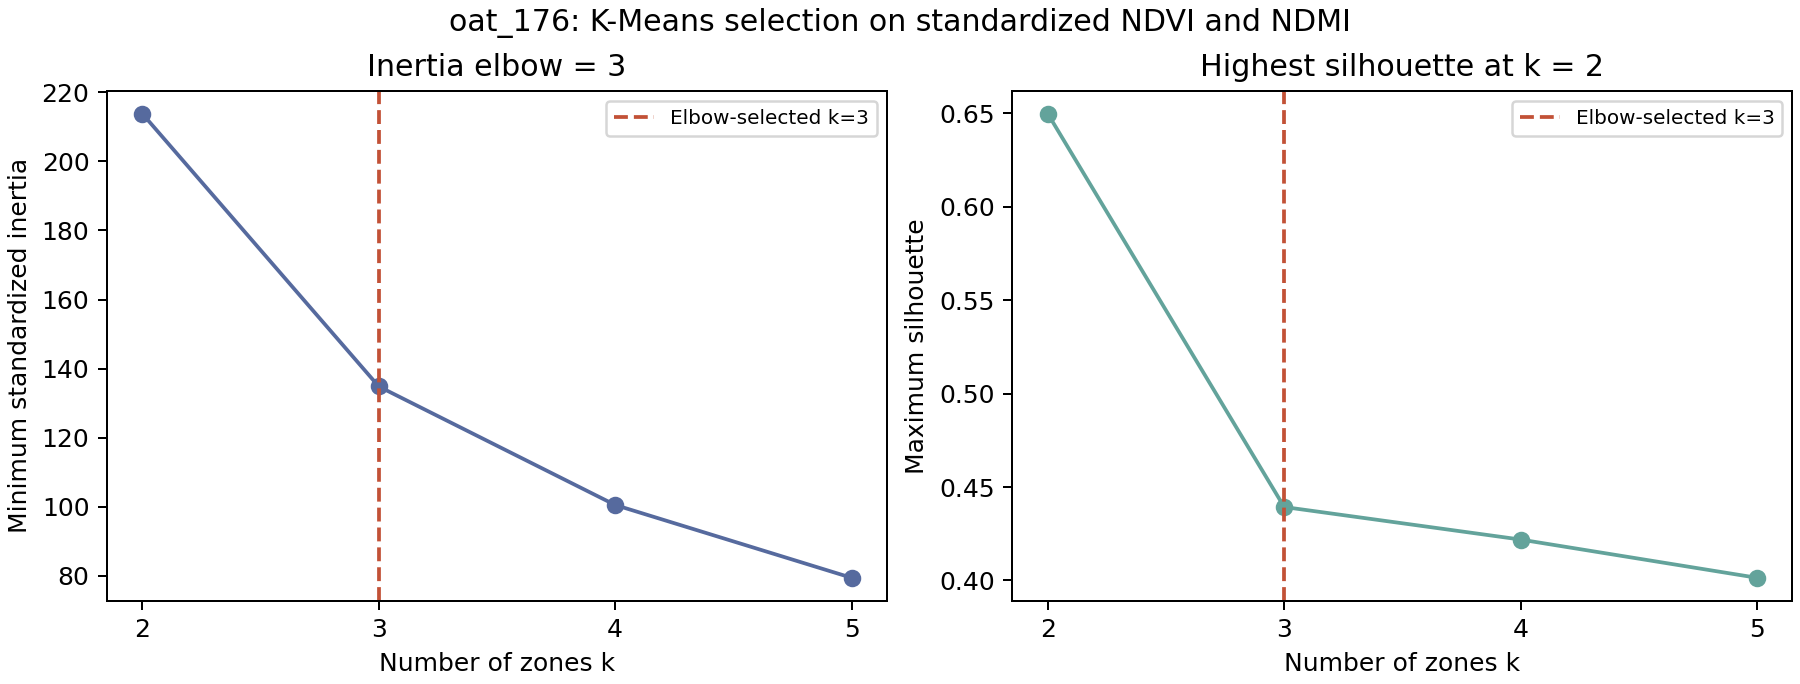

oat_107 — K-Means search


,k,init,n_init,silhouette,inertia,iterations,min_zone_fraction,feasible,elbow_distance
0,2,k-means++,10,0.623281,92.641107,4,0.272727,True,0.000000
1,2,k-means++,30,0.623281,92.641107,4,0.272727,True,0.000000
2,2,random,10,0.623281,92.641107,5,0.272727,True,0.000000
3,2,random,30,0.623281,92.641107,5,0.272727,True,0.000000
4,3,k-means++,10,0.568299,48.626008,7,0.195804,True,0.316804
5,3,k-means++,30,0.568299,48.626008,7,0.195804,True,0.316804
6,3,random,10,0.568299,48.626008,6,0.195804,True,0.316804
7,3,random,30,0.568299,48.626008,6,0.195804,True,0.316804
8,4,k-means++,10,0.519020,33.762869,8,0.146853,True,0.204875
9,4,k-means++,30,0.529928,33.636653,5,0.111888,True,0.204875


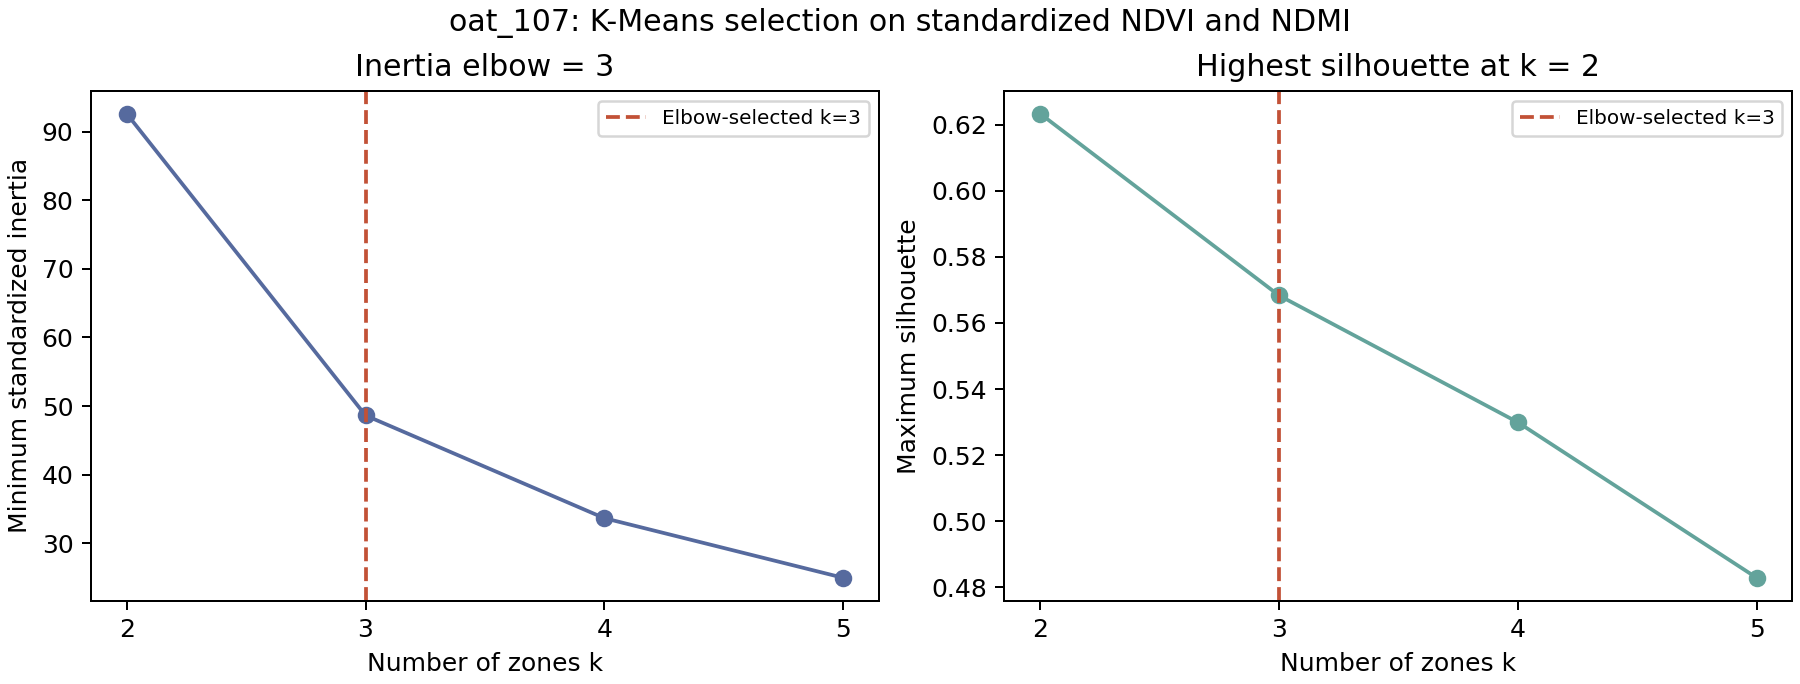

In [7]:
metric_table = run_analysis()
for field in config.FIELDS:
    print(field, "— K-Means search")
    display(pd.read_csv(config.OUTPUTS_DIR / field / "03_kmeans_search.csv"))
    display(Image(filename=str(config.OUTPUTS_DIR / field / "03_method_kmeans_elbow.png")))

## 3. Segmented results

Both fields are shown for all three methods in distinct four (baseline) and three-zone cluster figures. Colours rank zone mean NDVI & NDMI *within each model map*. To identify joint low NDVI and NDMI zones - mn3392g

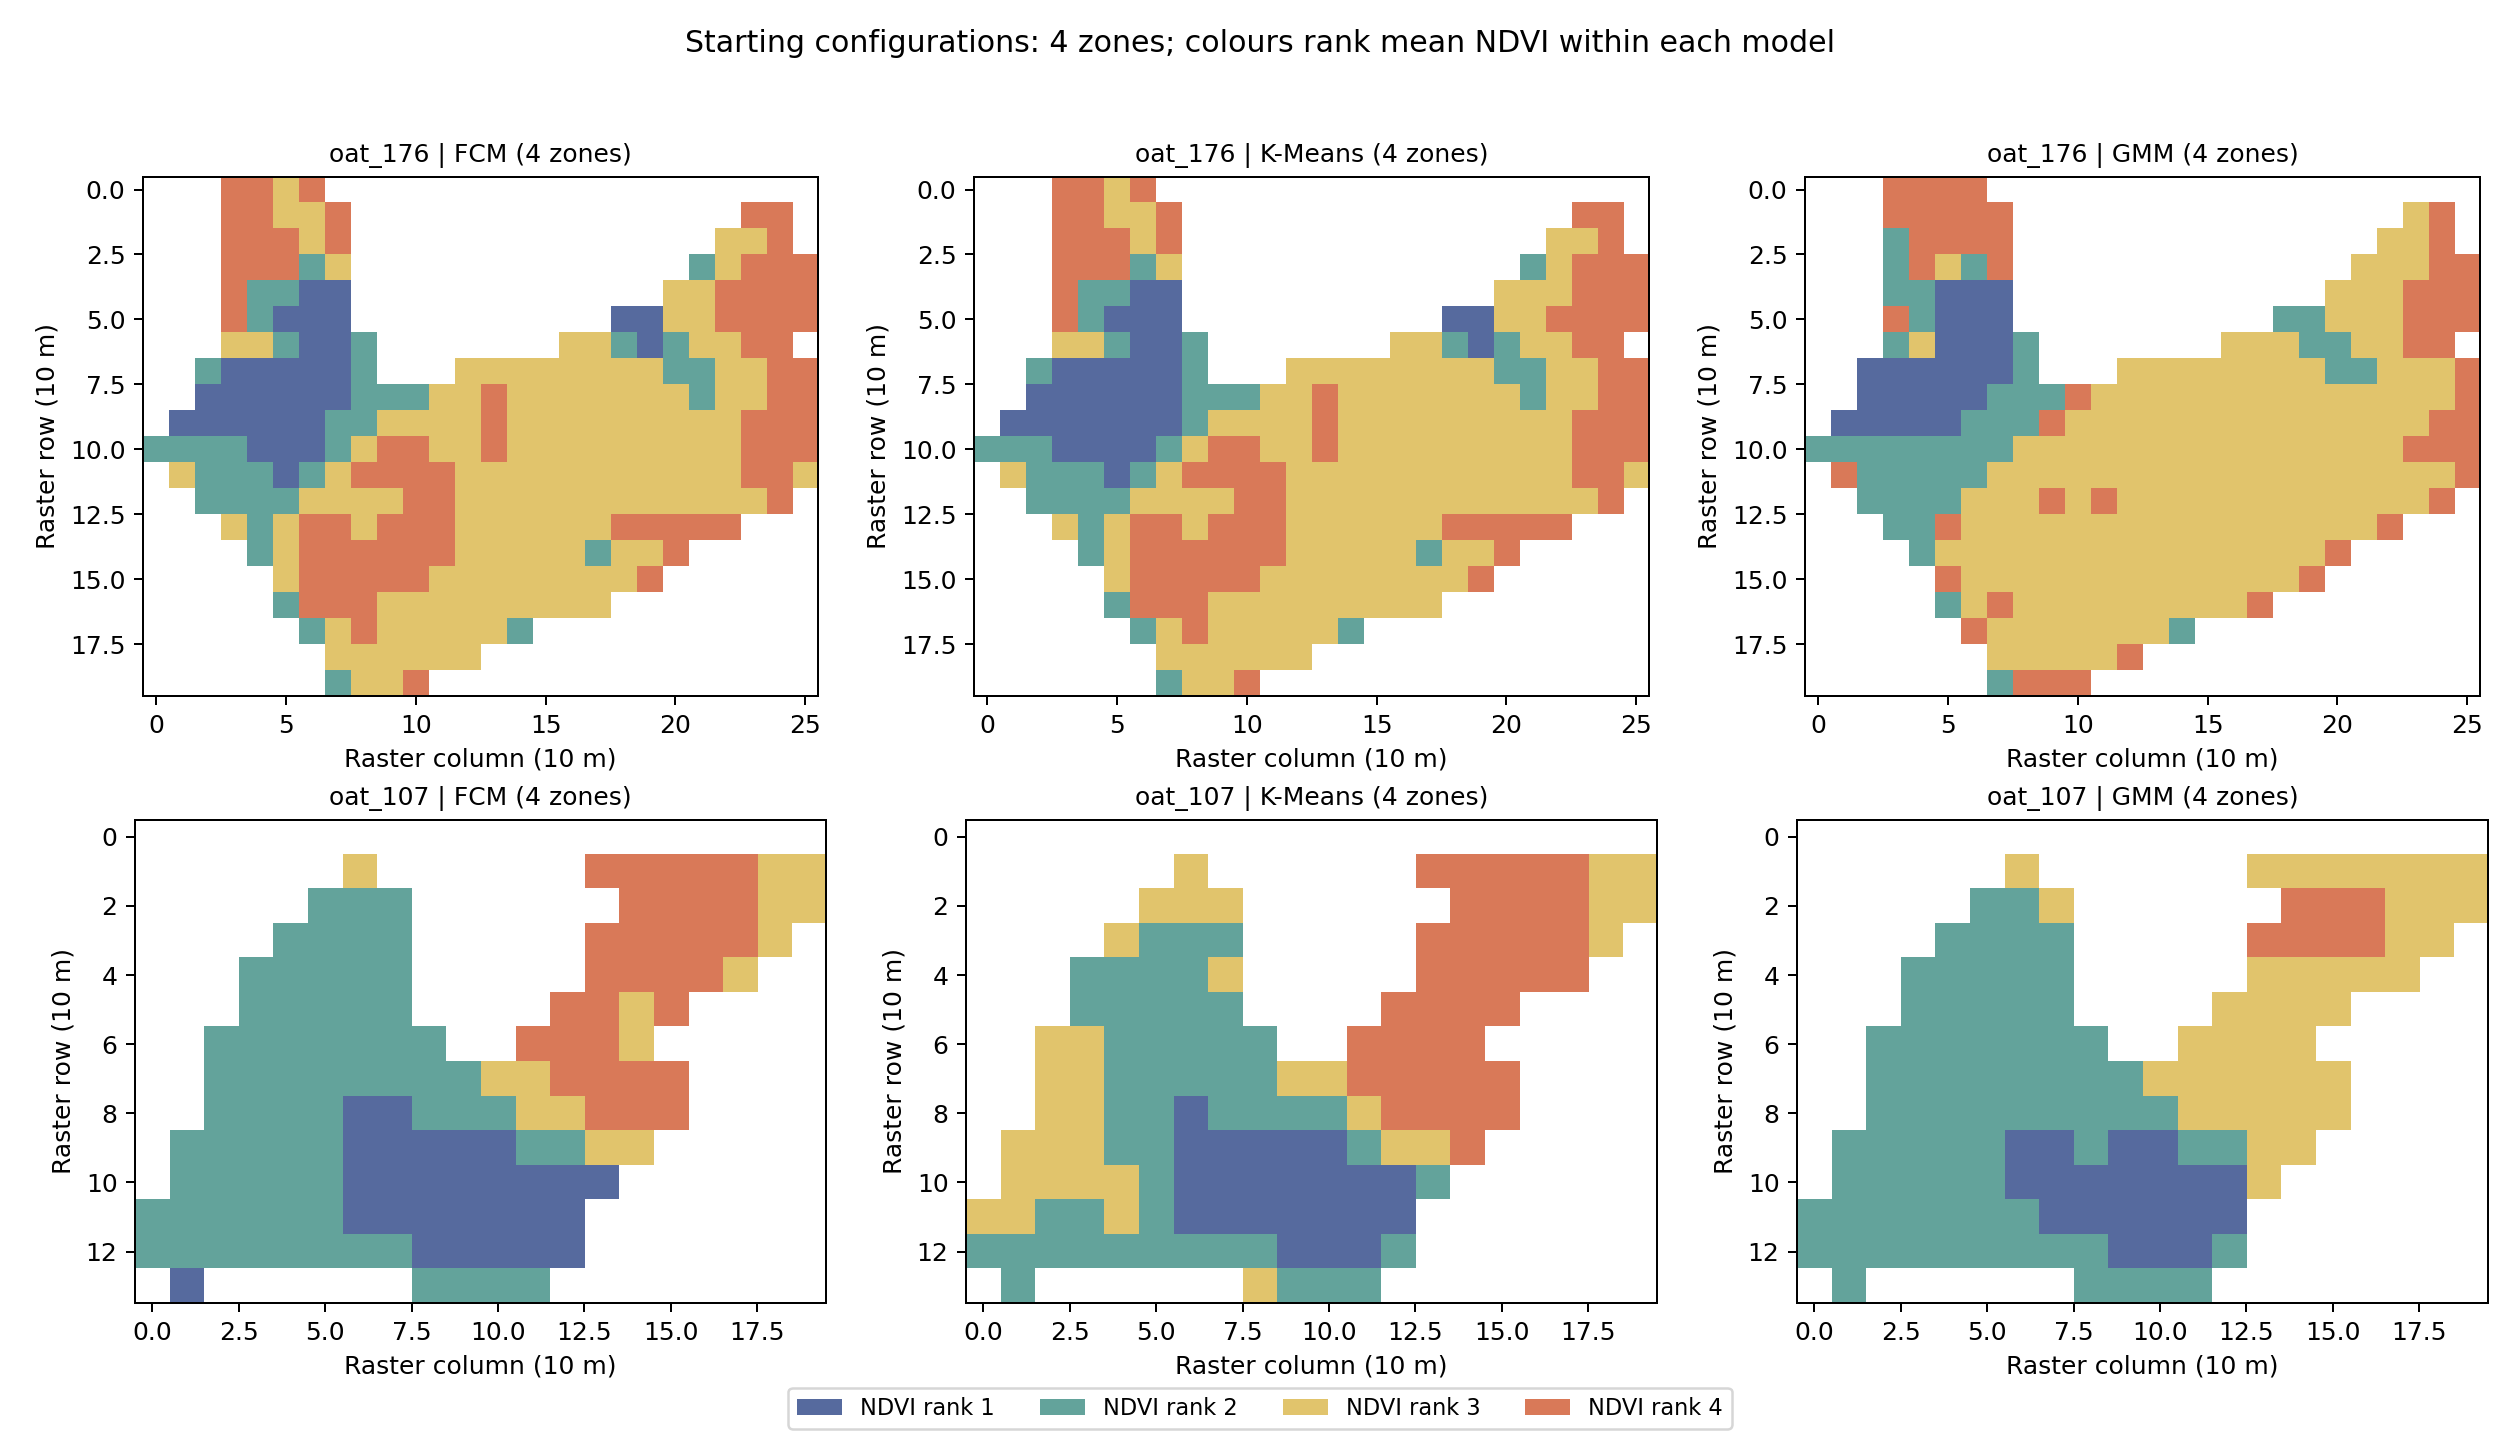

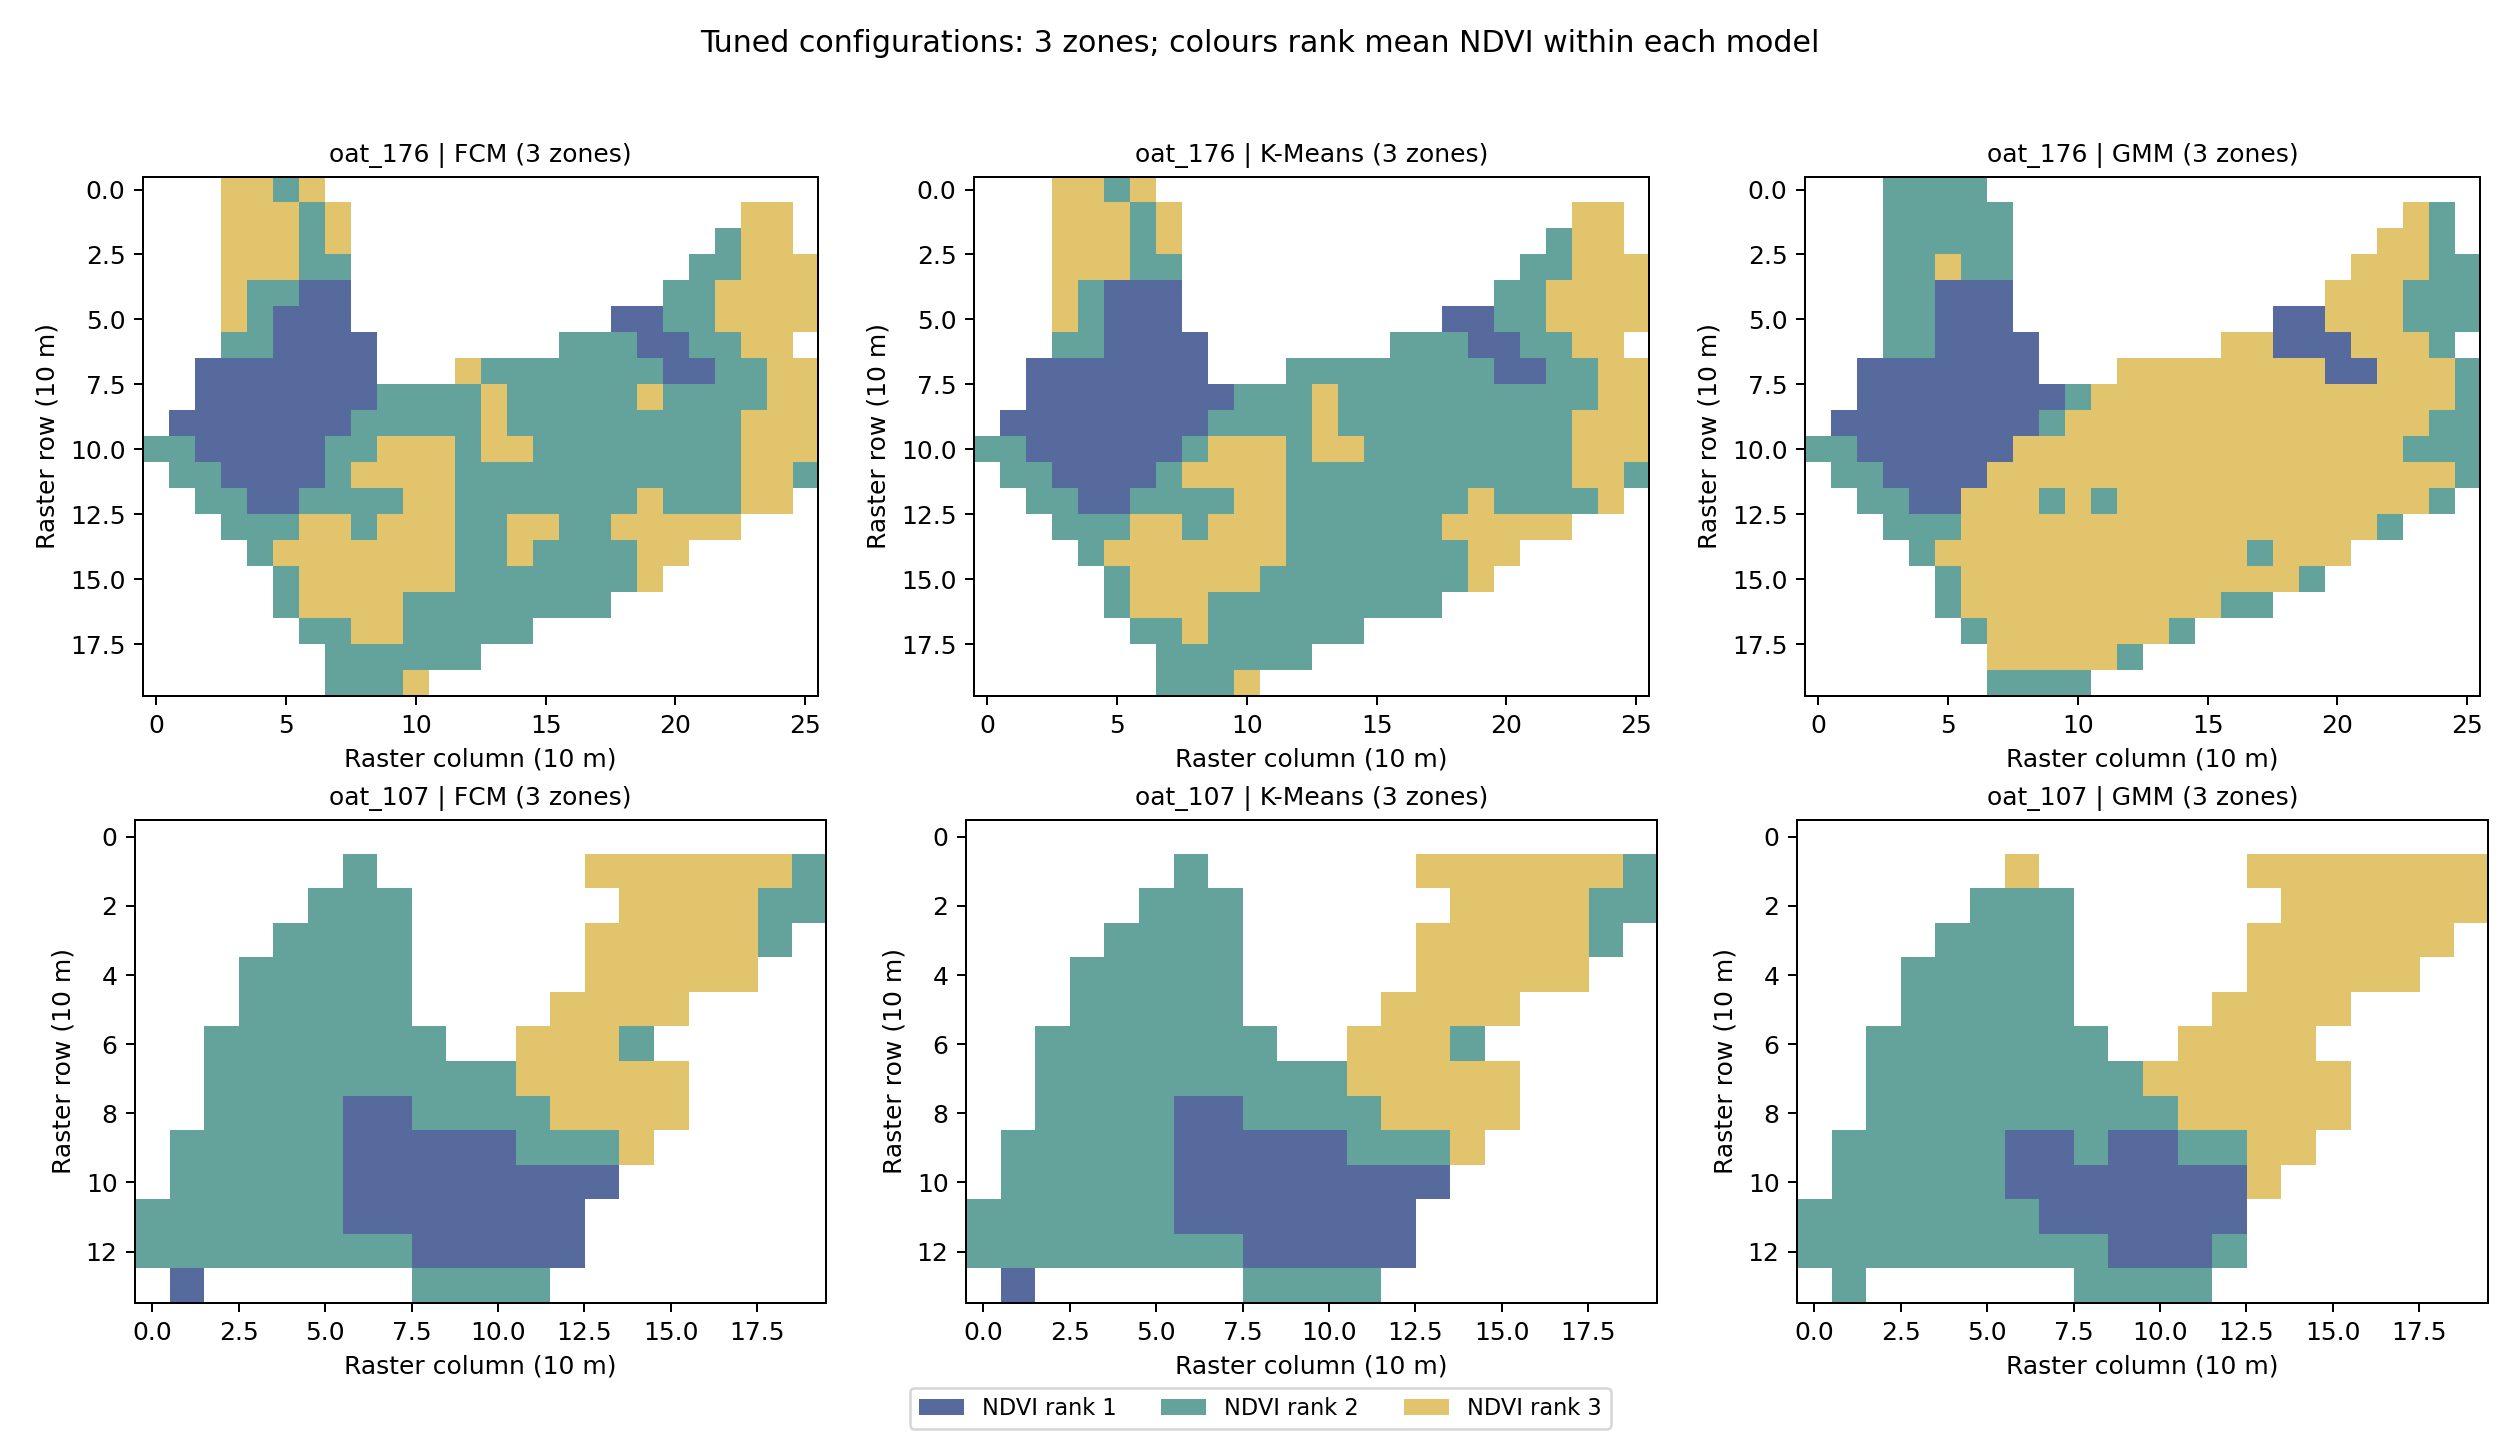

,cluster,pixels,ndvi_mean,ndmi_mean,ndvi_sd,ndmi_sd,hectares_approx,fraction_covered,field,model,relative_pattern
0,0,83,0.688919,0.107103,0.029295,0.031572,0.83,0.280405,oat_176,fcm_baseline,high NDVI / high NDMI
1,1,39,0.583285,-0.000240,0.023858,0.033682,0.39,0.131757,oat_176,fcm_baseline,low NDVI / low NDMI
2,2,31,0.493019,-0.075289,0.042117,0.027968,0.31,0.104730,oat_176,fcm_baseline,low NDVI / low NDMI
3,3,143,0.657966,0.047828,0.017616,0.018740,1.43,0.483108,oat_176,fcm_baseline,low NDVI / low NDMI
4,0,144,0.658302,0.047904,0.018009,0.018697,1.44,0.486486,oat_176,kmeans_baseline,low NDVI / low NDMI
5,1,33,0.496907,-0.074507,0.043642,0.027262,0.33,0.111486,oat_176,kmeans_baseline,low NDVI / low NDMI
6,2,82,0.688708,0.107693,0.029412,0.031301,0.82,0.277027,oat_176,kmeans_baseline,high NDVI / high NDMI
7,3,37,0.584696,0.003119,0.023682,0.031166,0.37,0.125000,oat_176,kmeans_baseline,low NDVI / low NDMI
8,0,54,0.674160,0.106923,0.042412,0.044169,0.54,0.182432,oat_176,gmm_baseline,high NDVI / high NDMI
9,1,25,0.479645,-0.062650,0.035565,0.043777,0.25,0.084459,oat_176,gmm_baseline,low NDVI / low NDMI


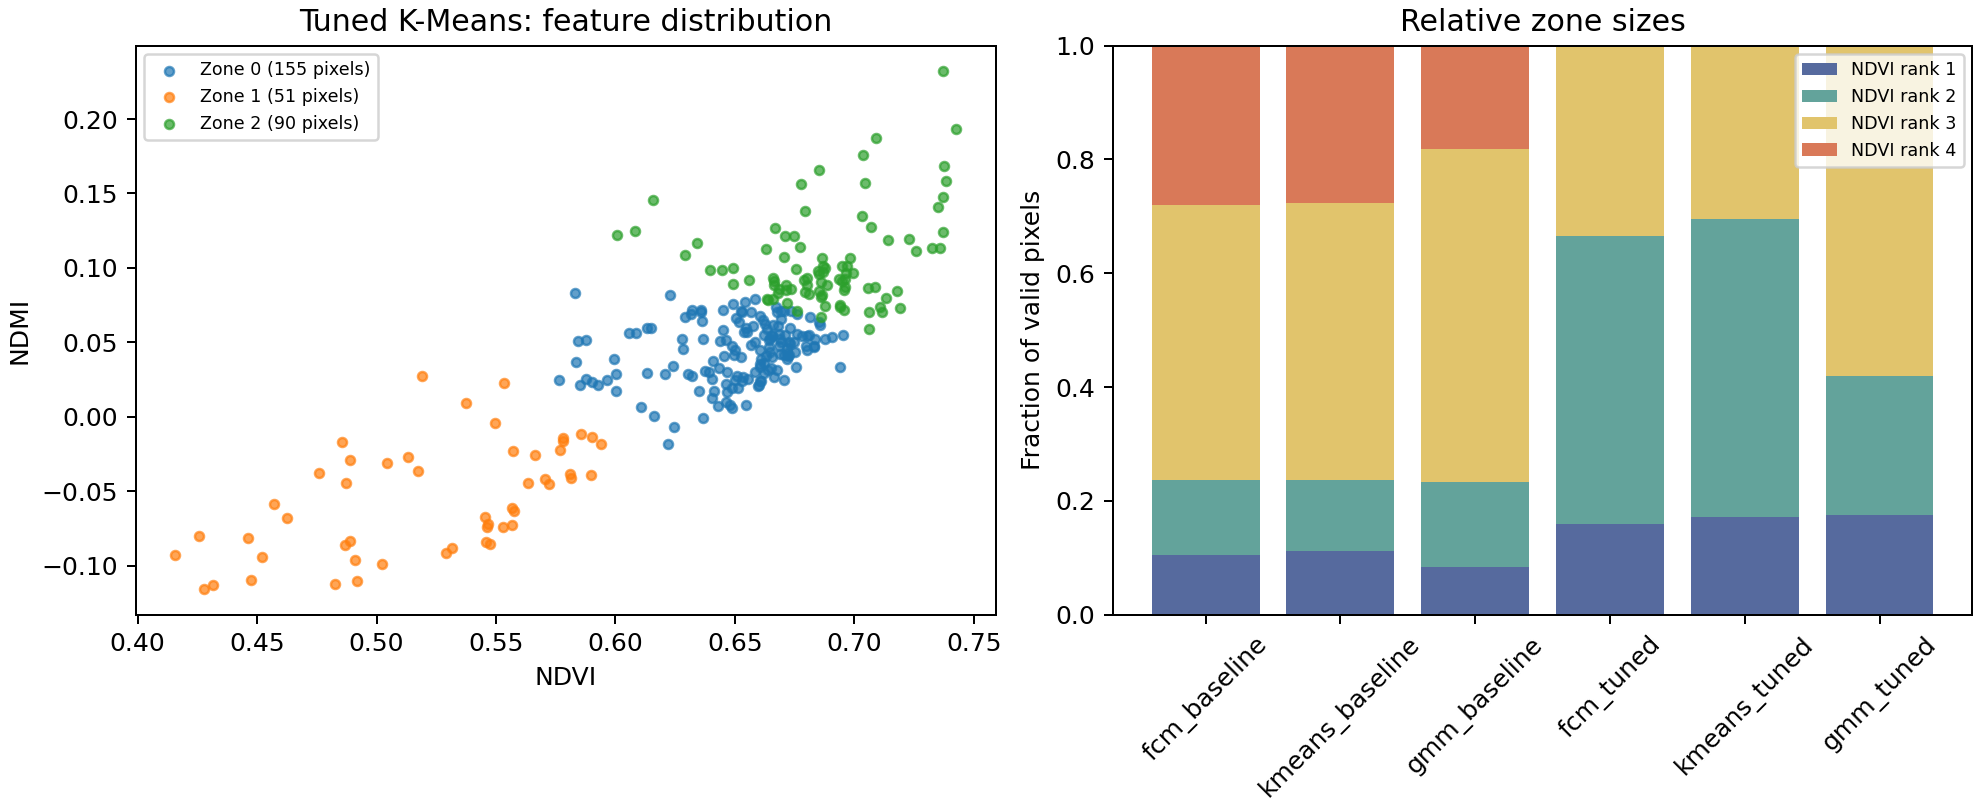

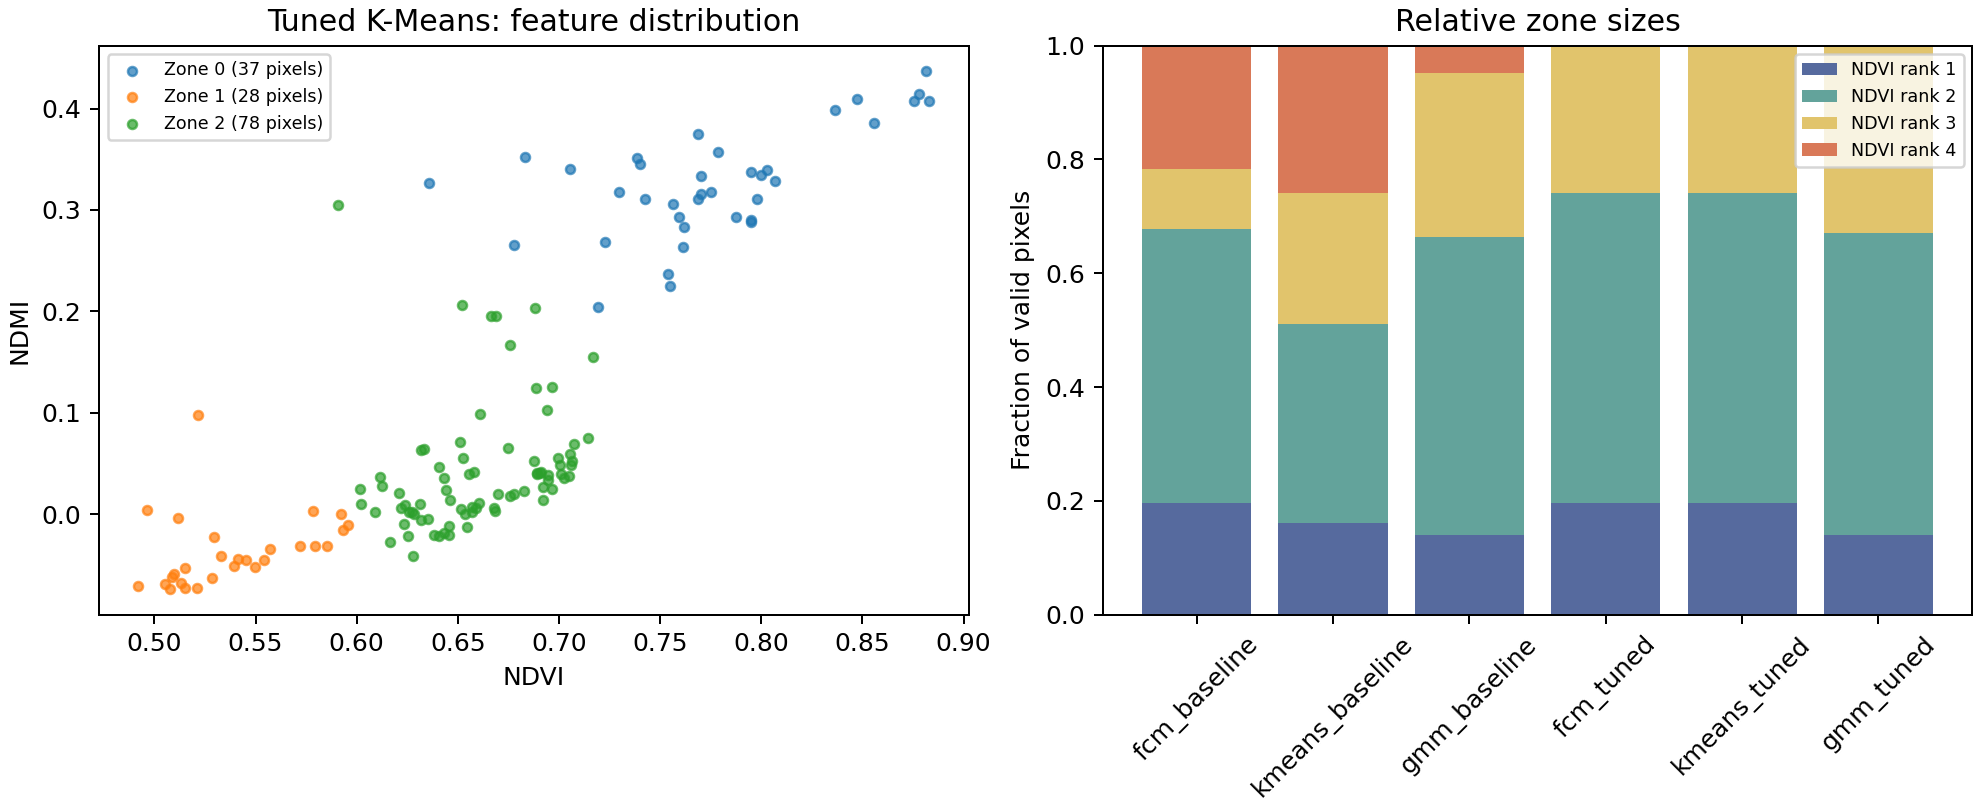

In [8]:
for figure in ["04a_results_baseline_k4.png", "04b_results_tuned_k3.png"]:
    display(Image(filename=str(config.OUTPUTS_DIR / figure)))
display(pd.read_csv(config.OUTPUTS_DIR / "08_zone_profiles.csv"))
for field in config.FIELDS:
    display(Image(filename=str(config.OUTPUTS_DIR / field / "06_results_distributions.png")))

## 4. Final Cluster Evaluation // k=3

,field,model,pixels,k,coverage,components,neighbour_agreement,silhouette,davies_bouldin,calinski_harabasz
0,oat_176,fcm_baseline,296,4,1.0,37,0.691450,0.421007,0.794457,469.979973
1,oat_176,kmeans_baseline,296,4,1.0,37,0.691450,0.423180,0.789350,474.761784
2,oat_176,gmm_baseline,296,4,1.0,32,0.778810,0.319479,1.222589,244.037451
3,oat_176,fcm_tuned,296,3,1.0,20,0.739777,0.429404,0.763357,495.155650
4,oat_176,kmeans_tuned,296,3,1.0,19,0.763941,0.439290,0.763619,496.647809
5,oat_176,gmm_tuned,296,3,1.0,22,0.817844,0.361002,1.733159,302.188456
6,oat_107,fcm_baseline,143,4,1.0,12,0.815574,0.522811,0.680338,335.608640
7,oat_107,kmeans_baseline,143,4,1.0,16,0.737705,0.480462,0.697552,289.936912
8,oat_107,gmm_baseline,143,4,1.0,8,0.831967,0.502694,0.545411,228.181443
9,oat_107,fcm_tuned,143,3,1.0,7,0.856557,0.568299,0.537460,341.713828


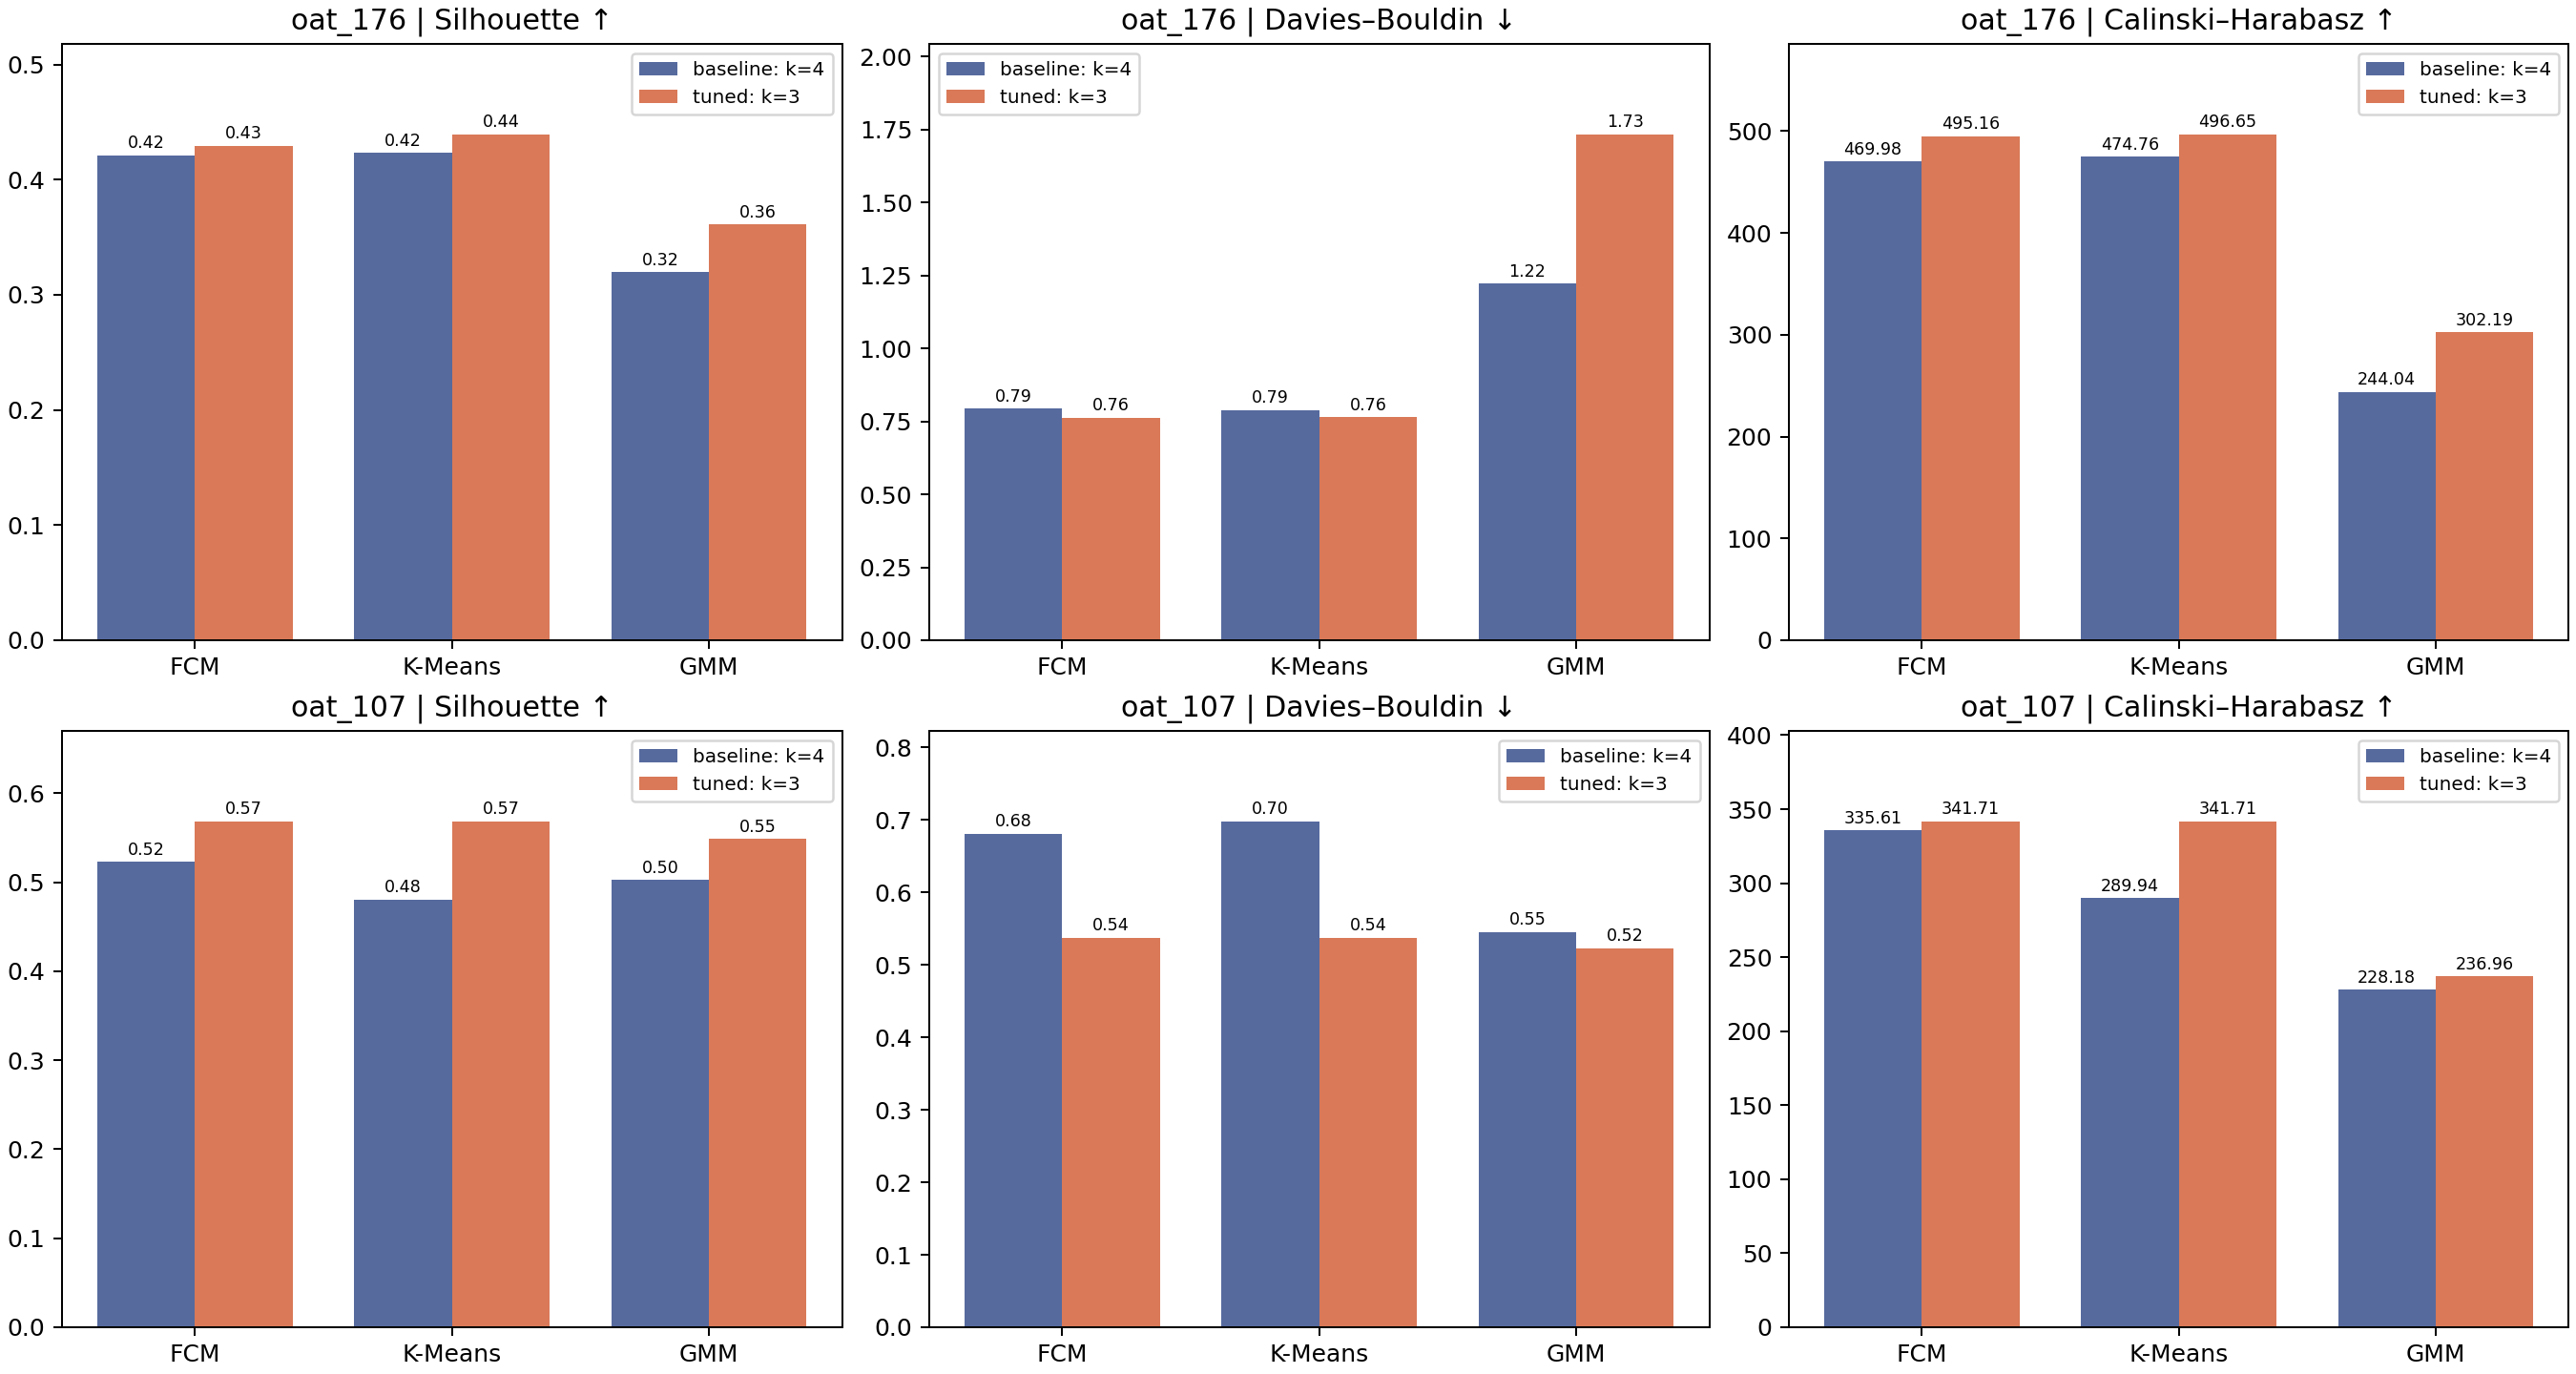

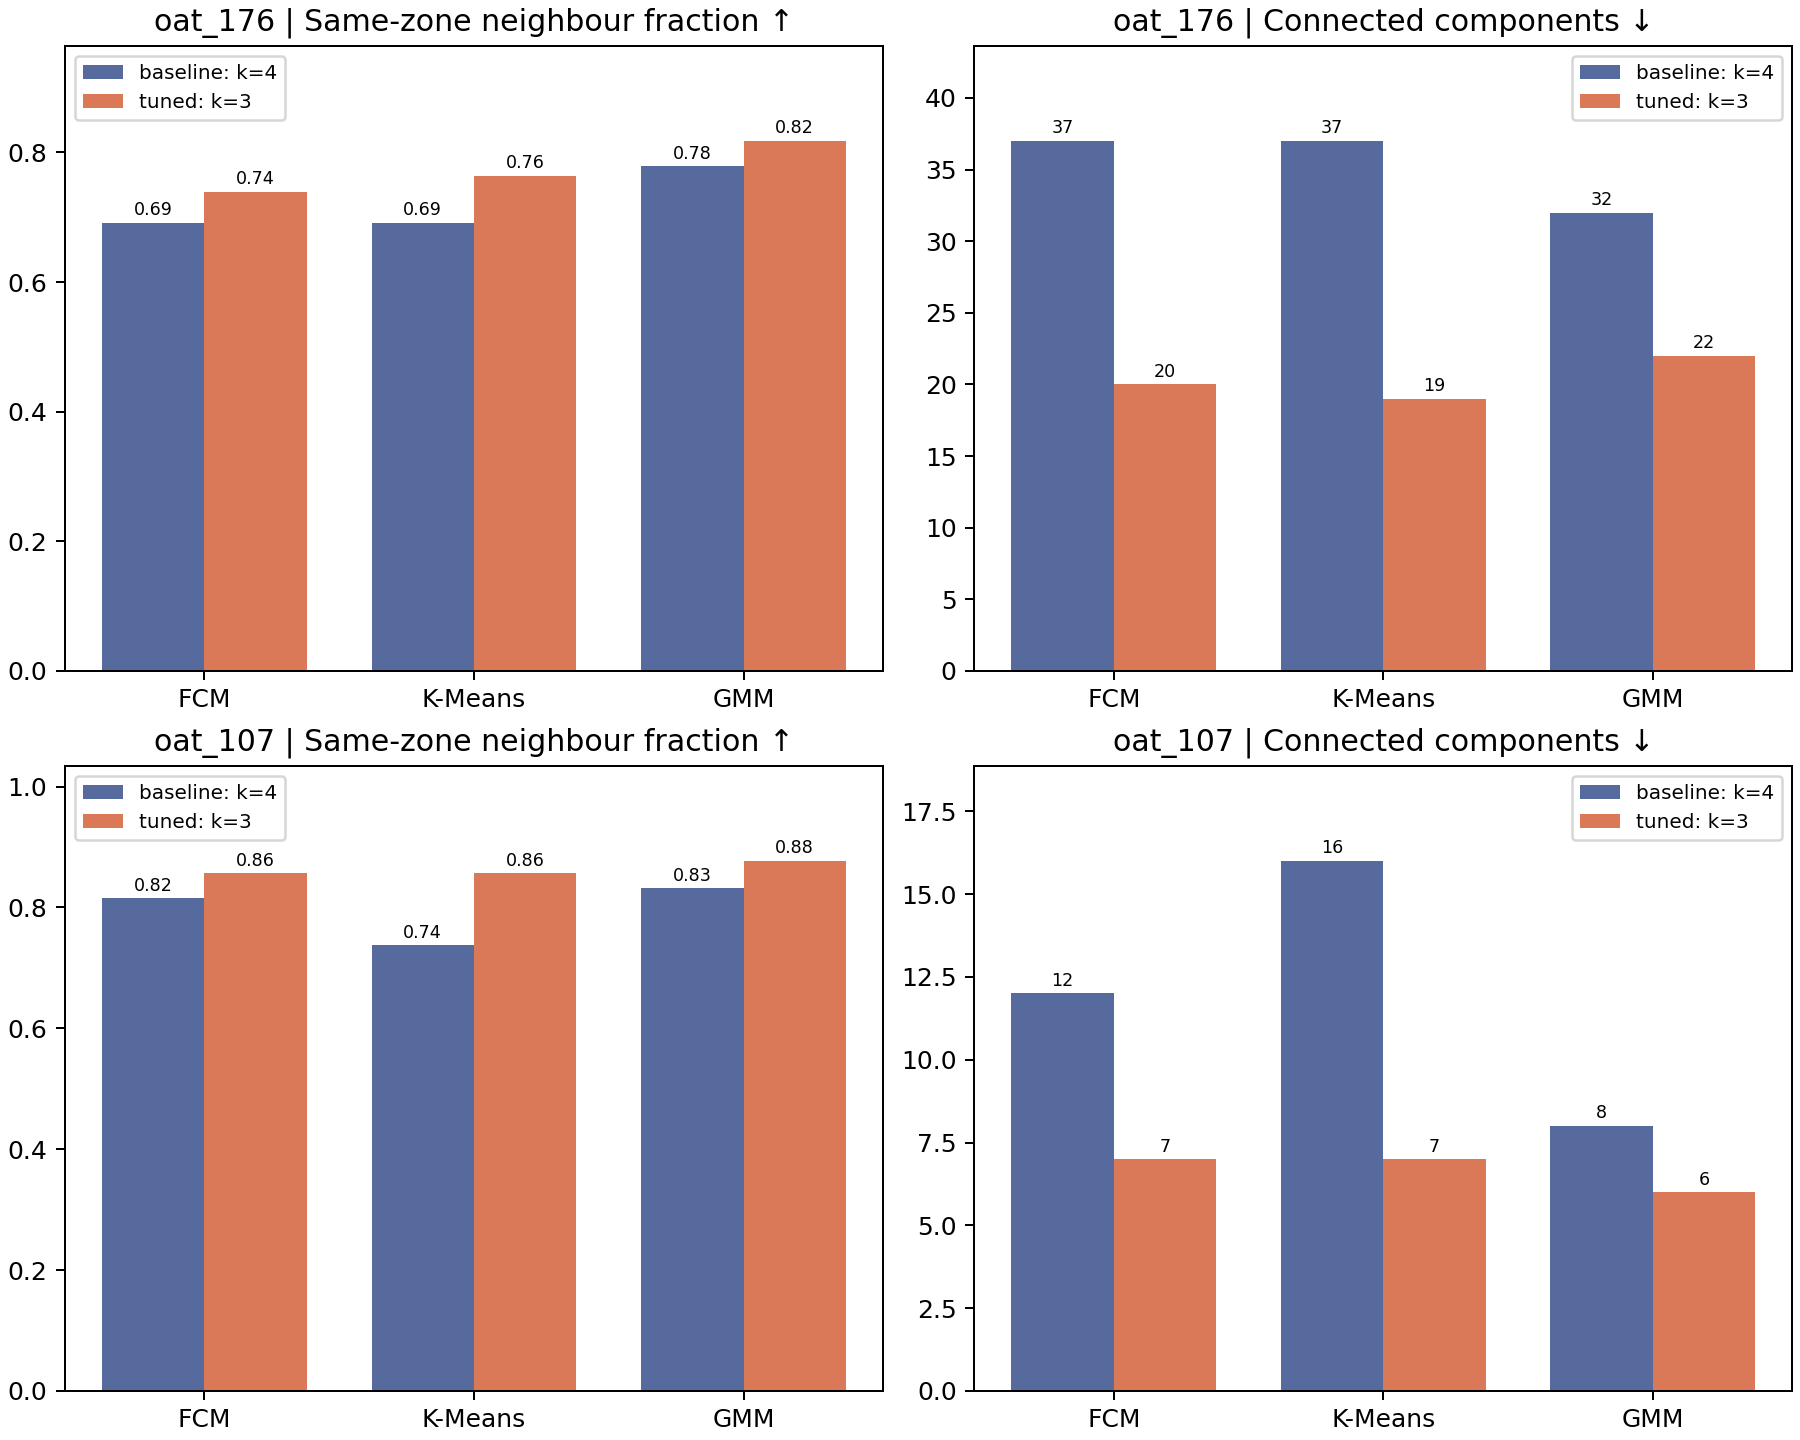

,field,comparator,ari_vs_kmeans,compared_fraction
0,oat_176,fcm_baseline,0.748375,1.0
1,oat_176,kmeans_baseline,0.741278,1.0
2,oat_176,gmm_baseline,0.328403,1.0
3,oat_176,fcm_tuned,0.860980,1.0
4,oat_176,gmm_tuned,0.347683,1.0
5,oat_107,fcm_baseline,0.817392,1.0
6,oat_107,kmeans_baseline,0.572662,1.0
7,oat_107,gmm_baseline,0.611318,1.0
8,oat_107,fcm_tuned,1.000000,1.0
9,oat_107,gmm_tuned,0.662074,1.0


In [9]:
display(metric_table)
for figure in ["07a_evaluation_cluster_quality.png", "07b_evaluation_spatial_coherence.png"]:
    display(Image(filename=str(config.OUTPUTS_DIR / figure)))
display(pd.read_csv(config.OUTPUTS_DIR / "09_model_agreement.csv"))

## 5. Reusable assignments

Each field and the shared root provide identical pixel assignments as CSV and Parquet. GeoTIFF outputs contain K-Means zone rasters for the two stages

In [10]:
for field in config.FIELDS:
    d = config.OUTPUTS_DIR / field
    print(field, d / "10_clustered_pixels.parquet", d / "10_clustered_pixels.csv")
    display(pd.read_csv(d / "10_clustered_pixels.csv").head())

oat_176 C:\Users\User\MSF_OneDrive\OneDrive\BSc Computer Science\Year 3\AI-1818\Research\ndvi_mz_mn3392g\ndvi_mz_mn3392g\outputs\oat_176\10_clustered_pixels.parquet C:\Users\User\MSF_OneDrive\OneDrive\BSc Computer Science\Year 3\AI-1818\Research\ndvi_mz_mn3392g\ndvi_mz_mn3392g\outputs\oat_176\10_clustered_pixels.csv


,field,fid,date,crs,row,col,x,y,ndvi,ndmi,model,cluster,uncertainty
0,oat_176,590,2024-03-28,EPSG:32717,0,3,851595.0,9138415.0,0.629026,0.108312,fcm_baseline,0,0.537886
1,oat_176,590,2024-03-28,EPSG:32717,0,4,851605.0,9138415.0,0.670562,0.107446,fcm_baseline,0,0.120000
2,oat_176,590,2024-03-28,EPSG:32717,0,5,851615.0,9138415.0,0.614916,0.059675,fcm_baseline,3,0.460897
3,oat_176,590,2024-03-28,EPSG:32717,0,6,851625.0,9138415.0,0.639687,0.098622,fcm_baseline,0,0.525213
4,oat_176,590,2024-03-28,EPSG:32717,1,3,851595.0,9138405.0,0.634294,0.116641,fcm_baseline,0,0.468817


oat_107 C:\Users\User\MSF_OneDrive\OneDrive\BSc Computer Science\Year 3\AI-1818\Research\ndvi_mz_mn3392g\ndvi_mz_mn3392g\outputs\oat_107\10_clustered_pixels.parquet C:\Users\User\MSF_OneDrive\OneDrive\BSc Computer Science\Year 3\AI-1818\Research\ndvi_mz_mn3392g\ndvi_mz_mn3392g\outputs\oat_107\10_clustered_pixels.csv


,field,fid,date,crs,row,col,x,y,ndvi,ndmi,model,cluster,uncertainty
0,oat_107,355,2024-03-28,EPSG:32717,1,6,851345.0,9138555.0,0.688654,0.124780,fcm_baseline,0,0.516218
1,oat_107,355,2024-03-28,EPSG:32717,1,13,851415.0,9138555.0,0.761502,0.263512,fcm_baseline,3,0.525062
2,oat_107,355,2024-03-28,EPSG:32717,1,14,851425.0,9138555.0,0.794998,0.289868,fcm_baseline,3,0.169406
3,oat_107,355,2024-03-28,EPSG:32717,1,15,851435.0,9138555.0,0.806813,0.328758,fcm_baseline,3,0.021948
4,oat_107,355,2024-03-28,EPSG:32717,1,16,851445.0,9138555.0,0.797837,0.310711,fcm_baseline,3,0.056988
